# FinSignal · Pipeline 1: Financial Sentiment Classification (Fine-tuning)
**ISOM5240 Group 7** · Company: **Wealthsimple** (https://www.wealthsimple.com/)
Fine-tuning owner: **SHI Yuebing**

**Objective.** Fine-tune `distilbert-base-uncased` to classify financial news as **Bearish / Bullish / Neutral**, the first pipeline of the FinSignal app for Wealthsimple.

**Notebook flow**
1. Setup (pinned libraries, seed, GPU check)
2. Load dataset from Hugging Face
3. Pre-processing: cleaning, label mapping, de-duplication, leakage removal, stratified split
4. Exploratory checks (class balance, token lengths)
5. Tokenisation
6. Fine-tuning with the Hugging Face `Trainer`
7. Evaluation on the held-out test set (accuracy, per-class report, confusion matrix, runtime)
8. Save / publish the fine-tuned model and the dataset files

> Run with **Runtime → Change runtime type → T4 GPU**, then **Runtime → Restart and run all**.
> Publishing to Hugging Face needs a Colab secret named `HF_TOKEN` (write access); without it the
> notebook still runs end-to-end and simply skips the upload.

## 1. Setup

In [1]:
# Pinned library versions (identical to the deployed Streamlit app's requirements.txt)
!pip -q install "transformers==4.57.1" "datasets==3.6.0" "accelerate==1.10.1" "huggingface_hub>=0.34,<1.0"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 59.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 33.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 374.9/374.9 kB 30.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 41.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 23.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 61.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incomp

In [2]:
import os, json, time, random, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from datasets import load_dataset, Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
import transformers
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, TrainingArguments, Trainer,
                          pipeline, set_seed)

SEED = 42
set_seed(SEED); random.seed(SEED); np.random.seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("transformers", transformers.__version__, "| torch", torch.__version__, "| device:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

transformers 4.57.1 | torch 2.11.0+cu130 | device: cuda
GPU: Tesla T4


In [3]:
# ---------------- configuration ----------------
HF_USERNAME   = "Ikenna14"            # <- Hugging Face account that hosts the models
BASE_MODEL    = "distilbert-base-uncased"    # pre-trained checkpoint from Hugging Face
DATASET_ID    = "zeroshot/twitter-financial-news-sentiment"
HUB_MODEL_ID  = f"{HF_USERNAME}/finsignal-sentiment-distilbert"
OUTPUT_DIR    = "finsignal-sentiment-distilbert"
DATA_DIR      = "data"
MAX_LEN       = 96       # covers >99% of headlines (checked in section 4)
LEARNING_RATE = 2e-5
EPOCHS        = 4
BATCH_SIZE    = 32
PUSH_TO_HUB   = True
os.makedirs(DATA_DIR, exist_ok=True)

## 2. Load the dataset

In [4]:
raw = load_dataset(DATASET_ID)
print(raw)
train_raw = raw["train"].to_pandas()
test_raw = raw["validation"].to_pandas()   # official held-out split -> our TEST set
train_raw.head()

README.md: 0.00B [00:00, ?B/s]

sent_train.csv: 0.00B [00:00, ?B/s]

sent_valid.csv: 0.00B [00:00, ?B/s]

Generating train split:   0%|          | 0/9543 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2388 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 9543
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2388
    })
})


,text,label
0,$BYND - JPMorgan reels in expectations on Beyo...,0
1,$CCL $RCL - Nomura points to bookings weakness...,0
2,"$CX - Cemex cut at Credit Suisse, J.P. Morgan ...",0
3,$ESS: BTIG Research cuts to Neutral https://t....,0
4,$FNKO - Funko slides after Piper Jaffray PT cu...,0


## 3. Pre-processing

**3.1 Text cleaning** — the same function is reused inside the Streamlit app, so training and inference text match exactly.

In [5]:
import html, re

_URL_RE = re.compile(r"https?://\S+|www\.\S+")
_WS_RE = re.compile(r"\s+")

def clean_text(text):
    """Unescape HTML entities (&amp; -> &), remove URLs, normalise whitespace.
    The exact same function is used in the Streamlit app (utils.py)."""
    if text is None:
        return ""
    text = html.unescape(str(text))
    text = _URL_RE.sub(" ", text)
    return _WS_RE.sub(" ", text).strip()

print(clean_text("Fed hikes rates by 25bp &amp; signals pause https://t.co/abc123  "))

Fed hikes rates by 25bp & signals pause


**3.2 Label definitions**

In [6]:
# Dataset card: LABEL_0 = Bearish, LABEL_1 = Bullish, LABEL_2 = Neutral
SENT_LABELS = ["Bearish", "Bullish", "Neutral"]
SENT_ID2LABEL = dict(enumerate(SENT_LABELS))
SENT_LABEL2ID = {v: k for k, v in SENT_ID2LABEL.items()}
SENT_ID2LABEL

{0: 'Bearish', 1: 'Bullish', 2: 'Neutral'}

**3.3 Clean, map labels, remove empty rows and duplicates, and remove any training text that also appears in the test set (prevents leakage).**

In [7]:
def prepare(df):
    out = pd.DataFrame({"text": df["text"].map(clean_text),
                        "label_name": df["label"].map(lambda y: SENT_ID2LABEL[int(y)])})
    out = out[out["text"].str.len() > 0]
    return out.drop_duplicates(subset="text").reset_index(drop=True)

train_all = prepare(train_raw)
test_df = prepare(test_raw)
before = len(train_all)
train_all = train_all[~train_all["text"].isin(set(test_df["text"]))].reset_index(drop=True)

print(f"train raw: {len(train_raw)} -> cleaned: {before} -> after leakage removal: {len(train_all)}")
print(f"test  raw: {len(test_raw)} -> cleaned: {len(test_df)}")

for d in (train_all, test_df):
    d["label"] = d["label_name"].map(SENT_LABEL2ID).astype(int)

train raw: 9543 -> cleaned: 9433 -> after leakage removal: 9401
test  raw: 2388 -> cleaned: 2377


**3.4 Stratified train / validation split** (90% / 10% of the training data). The test set is never used for training or model selection inside this notebook.

In [8]:
train_df, val_df = train_test_split(train_all, test_size=0.10, stratify=train_all["label"],
                                    random_state=SEED)
train_df, val_df = train_df.reset_index(drop=True), val_df.reset_index(drop=True)

split_sizes = pd.DataFrame({"split": ["train", "validation", "test"],
                            "samples": [len(train_df), len(val_df), len(test_df)]})
split_sizes

,split,samples
0,train,8460
1,validation,941
2,test,2377


## 4. Exploratory checks

,train,validation,test
label_name,,,
Bearish,1278,142,345
Bullish,1716,191,475
Neutral,5466,608,1557


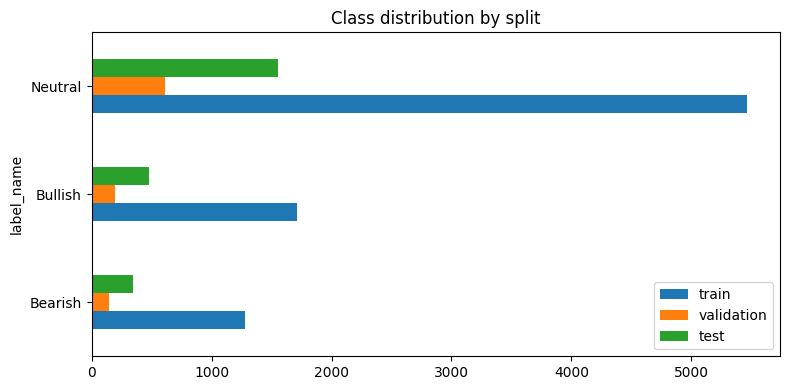

In [9]:
dist = pd.concat({"train": train_df["label_name"].value_counts(),
                  "validation": val_df["label_name"].value_counts(),
                  "test": test_df["label_name"].value_counts()}, axis=1).loc[SENT_LABELS]
display(dist)
dist.plot.barh(figsize=(8, 4), title="Class distribution by split"); plt.tight_layout(); plt.show()

In [10]:
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)
lengths = [len(x) for x in tokenizer(train_df["text"].tolist(), truncation=False)["input_ids"]]
print(f"token length  mean={np.mean(lengths):.1f}  p95={np.percentile(lengths, 95):.0f}  "
      f"p99={np.percentile(lengths, 99):.0f}  max={max(lengths)}")
print(f"share of samples <= MAX_LEN ({MAX_LEN}): {np.mean(np.array(lengths) <= MAX_LEN):.2%}")

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

token length  mean=19.6  p95=32  p99=38  max=81
share of samples <= MAX_LEN (96): 100.00%


## 5. Tokenisation

In [11]:
def to_hf(df):
    return Dataset.from_pandas(df[["text", "label"]], preserve_index=False)

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LEN)

train_ds = to_hf(train_df).map(tokenize, batched=True)
val_ds = to_hf(val_df).map(tokenize, batched=True)
test_ds = to_hf(test_df).map(tokenize, batched=True)
collator = DataCollatorWithPadding(tokenizer=tokenizer)
train_ds

Map:   0%|          | 0/8460 [00:00<?, ? examples/s]

Map:   0%|          | 0/941 [00:00<?, ? examples/s]

Map:   0%|          | 0/2377 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'label', 'input_ids', 'attention_mask'],
    num_rows: 8460
})

## 6. Fine-tuning

In [12]:
model = AutoModelForSequenceClassification.from_pretrained(
    BASE_MODEL, num_labels=len(SENT_LABELS),
    id2label=SENT_ID2LABEL, label2id=SENT_LABEL2ID)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds),
            "macro_f1": f1_score(labels, preds, average="macro")}

args = TrainingArguments(
    output_dir="checkpoints",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=128,
    num_train_epochs=EPOCHS,
    weight_decay=0.01,
    warmup_ratio=0.1,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,
    save_total_limit=2,
    fp16=torch.cuda.is_available(),
    logging_steps=50,
    report_to="none",
    seed=SEED,
)

trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                  processing_class=tokenizer, data_collator=collator,
                  compute_metrics=compute_metrics)

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [13]:
t0 = time.perf_counter()
train_result = trainer.train()
train_minutes = (time.perf_counter() - t0) / 60
print(f"Training time: {train_minutes:.1f} min")

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.491100,0.516892,0.798087,0.744200
2,0.365600,0.422055,0.853348,0.803280
3,0.251900,0.429159,0.857598,0.820464
4,0.176000,0.454461,0.858661,0.819387


Training time: 2.7 min


,epoch,eval_loss,eval_accuracy,eval_macro_f1
0,1.0,0.516892,0.798087,0.744200
1,2.0,0.422055,0.853348,0.803280
2,3.0,0.429159,0.857598,0.820464
3,4.0,0.454461,0.858661,0.819387


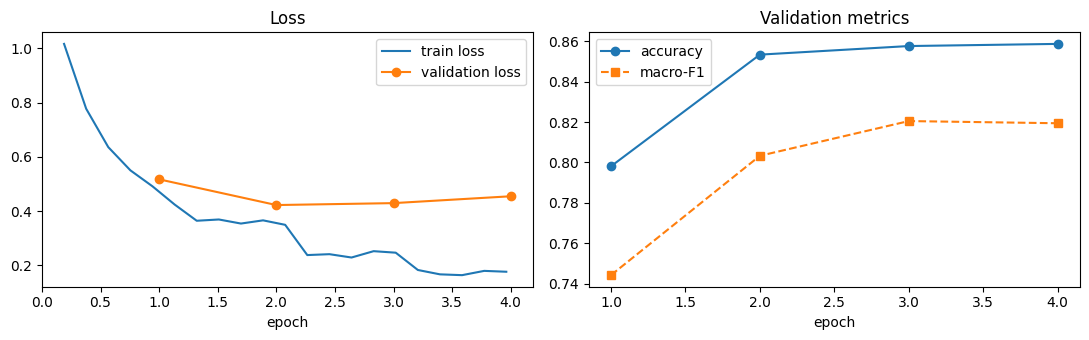

In [14]:
hist = pd.DataFrame(trainer.state.log_history)
epoch_log = hist.dropna(subset=["eval_accuracy"])[["epoch", "eval_loss", "eval_accuracy", "eval_macro_f1"]]
train_loss = hist.dropna(subset=["loss"])[["step", "epoch", "loss"]]
display(epoch_log.reset_index(drop=True))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(train_loss["epoch"], train_loss["loss"], label="train loss")
ax[0].plot(epoch_log["epoch"], epoch_log["eval_loss"], "o-", label="validation loss")
ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].set_title("Loss")
ax[1].plot(epoch_log["epoch"], epoch_log["eval_accuracy"], "o-", label="accuracy")
ax[1].plot(epoch_log["epoch"], epoch_log["eval_macro_f1"], "s--", label="macro-F1")
ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].set_title("Validation metrics")
plt.tight_layout(); plt.show()

## 7. Evaluation on the held-out test set

In [15]:
t0 = time.perf_counter()
pred_out = trainer.predict(test_ds)
test_seconds = time.perf_counter() - t0
y_true = pred_out.label_ids
y_pred = np.argmax(pred_out.predictions, axis=-1)

test_acc = accuracy_score(y_true, y_pred)
test_f1 = f1_score(y_true, y_pred, average="macro")
print(f"TEST accuracy = {test_acc:.4f} | macro-F1 = {test_f1:.4f} | "
      f"{len(y_true)} samples in {test_seconds:.1f}s ({test_seconds/len(y_true)*1000:.2f} ms/sample on {DEVICE})")
print()
print(classification_report(y_true, y_pred, target_names=SENT_LABELS, digits=4))

TEST accuracy = 0.8734 | macro-F1 = 0.8350 | 2377 samples in 0.8s (0.33 ms/sample on cuda)

              precision    recall  f1-score   support

     Bearish     0.7534    0.8058    0.7787       345
     Bullish     0.8215    0.8042    0.8128       475
     Neutral     0.9177    0.9094    0.9135      1557

    accuracy                         0.8734      2377
   macro avg     0.8309    0.8398    0.8350      2377
weighted avg     0.8746    0.8734    0.8738      2377



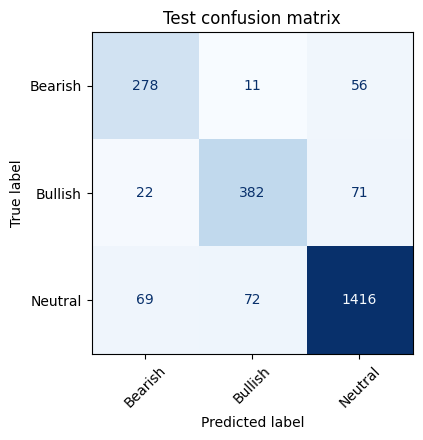

In [16]:
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(7, 7) if len(SENT_LABELS) > 3 else (4.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=SENT_LABELS).plot(ax=ax, cmap="Blues", colorbar=False,
                                                             xticks_rotation=45)
ax.set_title("Test confusion matrix"); plt.tight_layout(); plt.show()

In [17]:
# A few misclassified test examples (error analysis)
errors = test_df.assign(predicted=[SENT_ID2LABEL[i] for i in y_pred])
errors = errors[errors["label"] != y_pred][["text", "label_name", "predicted"]]
print(f"{len(errors)} misclassified test samples")
errors.head(10)

301 misclassified test samples


,text,label_name,predicted
5,$TAP - Barclays cools on Molson Coors,Bearish,Bullish
7,"Analysts Eviscerate Musk's Cybertruck: ""0% Of ...",Bearish,Bullish
8,Barclays assigns only a 20% chance that studie...,Bearish,Neutral
61,Highlight: Edward Jones Sr. Equity Analyst Jen...,Bullish,Neutral
74,Peloton bulls defend the upside case,Bullish,Neutral
75,Piper Jaffray analyst Erinn Murphy reiterated ...,Bullish,Neutral
94,Analysts Expect Breakeven For China Online Edu...,Neutral,Bullish
98,Mitek bull calls pullback 'an overreaction',Neutral,Bearish
99,Peabody Energy started at hold at Benchmark,Neutral,Bullish
102,"Tenable Holdings, Inc. Just Released Its Third...",Neutral,Bullish


## 8. Save, publish and package

In [18]:
# Save the best model (+ tokenizer) and a metrics file
trainer.save_model(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)

metrics = {
    "base_model": BASE_MODEL, "dataset": DATASET_ID, "labels": SENT_LABELS,
    "train_samples": len(train_df), "validation_samples": len(val_df), "test_samples": len(test_df),
    "epochs": EPOCHS, "learning_rate": LEARNING_RATE, "batch_size": BATCH_SIZE, "max_len": MAX_LEN,
    "best_validation_accuracy": float(epoch_log["eval_accuracy"].max()),
    "test_accuracy": float(test_acc), "test_macro_f1": float(test_f1),
    "training_minutes": round(train_minutes, 2),
    "test_ms_per_sample": round(test_seconds / len(y_true) * 1000, 3), "device": DEVICE,
    "epoch_log": epoch_log.round(4).to_dict(orient="records"),
}
with open(os.path.join(OUTPUT_DIR, "training_metrics.json"), "w") as f:
    json.dump(metrics, f, indent=2)

card_lines = [
    "---", "license: apache-2.0", f"base_model: {BASE_MODEL}", f"datasets: [{DATASET_ID}]",
    "pipeline_tag: text-classification", "language: en", "---",
    f"# {HUB_MODEL_ID}",
    f"FinSignal (ISOM5240 Group 7, for Wealthsimple). Fine-tuned from `{BASE_MODEL}` on `{DATASET_ID}`.",
    "", f"Labels: {', '.join(SENT_LABELS)}", "",
    "| metric (held-out test) | value |", "|---|---|",
    f"| accuracy | {test_acc:.4f} |", f"| macro-F1 | {test_f1:.4f} |",
    f"| test samples | {len(test_df)} |",
]
with open(os.path.join(OUTPUT_DIR, "README.md"), "w") as f:
    f.write("\n".join(card_lines))

# Dataset files used for fine-tuning and testing (for the submission folder)
train_df.to_csv(f"{DATA_DIR}/sentiment_train.csv", index=False)
val_df.to_csv(f"{DATA_DIR}/sentiment_validation.csv", index=False)
test_df.to_csv(f"{DATA_DIR}/sentiment_test.csv", index=False)
print(json.dumps({k: v for k, v in metrics.items() if k != "epoch_log"}, indent=2))

{
  "base_model": "distilbert-base-uncased",
  "dataset": "zeroshot/twitter-financial-news-sentiment",
  "labels": [
    "Bearish",
    "Bullish",
    "Neutral"
  ],
  "train_samples": 8460,
  "validation_samples": 941,
  "test_samples": 2377,
  "epochs": 4,
  "learning_rate": 2e-05,
  "batch_size": 32,
  "max_len": 96,
  "best_validation_accuracy": 0.8586609989373007,
  "test_accuracy": 0.873369793857804,
  "test_macro_f1": 0.8350086097124735,
  "training_minutes": 2.68,
  "test_ms_per_sample": 0.331,
  "device": "cuda"
}


In [19]:
# Publish to Hugging Face (needs Colab secret HF_TOKEN with write access)
token = None
try:
    from google.colab import userdata
    token = userdata.get("HF_TOKEN")
except Exception as e:
    token = os.environ.get("HF_TOKEN")

if PUSH_TO_HUB and token:
    from huggingface_hub import create_repo, upload_folder
    create_repo(HUB_MODEL_ID, token=token, exist_ok=True, private=False)
    upload_folder(repo_id=HUB_MODEL_ID, folder_path=OUTPUT_DIR, token=token,
                  commit_message="FinSignal fine-tuned model")
    print("Published: https://huggingface.co/" + HUB_MODEL_ID)
else:
    print("HF_TOKEN not available -> skipped upload (model saved locally in ./" + OUTPUT_DIR + ")")

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...tilbert/model.safetensors:   0%|          |  575kB /  268MB            

  ...tilbert/training_args.bin:  23%|##3       | 1.36kB / 5.84kB            

Published: https://huggingface.co/Ikenna14/finsignal-sentiment-distilbert


In [20]:
# Sanity check: reload the saved model through a Hugging Face pipeline (exactly how the app uses it)
clf = pipeline("text-classification", model=OUTPUT_DIR, tokenizer=OUTPUT_DIR,
               device=0 if DEVICE == "cuda" else -1)
examples = ['Retailer shares tumble after it slashes full-year profit forecast', 'Software maker beats revenue estimates and raises annual outlook', 'Company to present at investor conference next week']
for text, res in zip(examples, clf([clean_text(x) for x in examples], truncation=True, max_length=MAX_LEN)):
    print(f"{res['label']:<20} {res['score']:.3f}  {text}")

Device set to use cuda:0


Bearish              0.972  Retailer shares tumble after it slashes full-year profit forecast
Bullish              0.887  Software maker beats revenue estimates and raises annual outlook
Neutral              0.994  Company to present at investor conference next week


In [21]:
# Zip the model and data folders for the submission package
shutil.make_archive(OUTPUT_DIR, "zip", OUTPUT_DIR)
shutil.make_archive(f"{OUTPUT_DIR}_data", "zip", DATA_DIR)
print(os.listdir("."))
try:
    from google.colab import files
    files.download(f"{OUTPUT_DIR}.zip"); files.download(f"{OUTPUT_DIR}_data.zip")
except Exception:
    pass

['.config', 'finsignal-sentiment-distilbert_data.zip', 'data', 'checkpoints', 'finsignal-sentiment-distilbert', 'finsignal-sentiment-distilbert.zip', 'sample_data']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>